# Previsão de Falha em Máquinas com Aprendizagem Incremental

Este notebook aborda a criação de dados artificiais e a implementação de um processo de aprendizagem incremental para prever falhas em máquinas.

Vamos construir um processo de aprendizagem de tipo incremental, para isso é necessário construir um grupo de conjuntos artificiais de
maneira manual e formar uma árvore de classificação para prever quando se produz uma falha ao executar um processo incremental.

Para isso, deve utilizar-se o seguinte dataset de Kaggle e cumprir as seguintes normas:

https://www.kaggle.com/c/machine-failure-prediction/data

• Construir um processo de criação dos dados artificiais.

• Construir um processo de aprendizagem incremental com um algoritmo de Aprendizagem Automática de seleção.

## 1. Configuração Inicial e Carregamento dos Dados

In [ ]:
# Instalar os packages necessários
%pip install pandas numpy scikit-learn matplotlib seaborn

In [ ]:
# Importar bibliotecas necessárias
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import SGDClassifier

# Carregar datasets
# Ficheiro de treino
# Ficheiro de teste
# Ficheiro de submissão (resultado)
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')
df_sample = pd.read_csv('sample.csv')


Note: you may need to restart the kernel to use updated packages.


## 2. Visualização dos Dados Originais

In [ ]:
# Visualizar os cabeçalhos de cada ficheiro
print("Dados de treino:")
print(df_train.head())
print("\nDados de teste:")
print(df_test.head())

Train data:
   ID              Date  Temperature  Humidity   Operator  Measure1  Measure2  \
0   1  01-01-2016 00:00           67        82  Operator1       291         1   
1   2  01-01-2016 01:00           68        77  Operator1      1180         1   
2   3  01-01-2016 02:00           64        76  Operator1      1406         1   
3   4  01-01-2016 03:00           63        80  Operator1       550         1   
4   5  01-01-2016 04:00           65        81  Operator1      1928         1   

   Measure3  Measure4  Measure5  ...  Measure15  Hours Since Previous Failure  \
0         1      1041       846  ...       1842                            90   
1         1      1915      1194  ...        748                            91   
2         1       511      1577  ...       1689                            92   
3         1      1754      1834  ...        711                            93   
4         2      1326      1082  ...        507                            94   

   Failure  ?D

## 3. Preprocessamento e Análise Exploratória (EDA)

In [ ]:
# Unir os datasets para garantir um pré-processamento consistente
# Esta etapa serve apenas para transformar colunas categóricas
all_data = pd.concat([df_train.drop('Failure', axis=1), df_test], axis=0)

# Codificar coluna 'Operator'
all_data['Operator'] = all_data['Operator'].astype('category').cat.codes

# Separar novamente em treino e teste
df_train_preprocessed = all_data[:len(df_train)].copy()
df_test_preprocessed = all_data[len(df_train):].copy()

# Adicionar novamente a coluna 'Failure' ao dataframe de treino
df_train_preprocessed['Failure'] = df_train['Failure']

# Remover colunas desnecessárias (por exemplo, 'ID')
df_train_preprocessed = df_train_preprocessed.drop(columns=['ID'])
df_test_preprocessed = df_test_preprocessed.drop(columns=['ID'])

# Definir as variáveis X e y para o conjunto de treino
X_base = df_train_preprocessed.drop(columns=['Failure'])
y_base = df_train_preprocessed['Failure']

# Mapear a variável alvo para valores numéricos, se necessário
y_base = y_base.astype('category').cat.codes

# Remover ou converter colunas não numéricas (por exemplo, 'Date' ou 'Time')
for col in X_base.columns:
    if X_base[col].dtype == 'object':
        print(f"A remover coluna não numérica: {col}")
        X_base = X_base.drop(columns=[col])
        df_test_preprocessed = df_test_preprocessed.drop(columns=[col])

# Dividir os dados de treino em conjunto inicial e fluxo para simular aprendizagem incremental
X_initial, X_stream, y_initial, y_stream = train_test_split(X_base, y_base, test_size=0.8, random_state=42, stratify=y_base)

# Mostrar dimensões para confirmação
print(f"Dimensões do conjunto de treino inicial: {X_initial.shape}")
print(f"Dimensões do conjunto de fluxo: {X_stream.shape}")

Removing non-numeric column: Date
Dimensions of the initial training set: (1581, 26)
Dimensions of the 'stream' set: (6324, 26)


## 4. Processo de Criação de Dados Artificiais

In [ ]:
def create_data_chunk(X_df, y_df, chunk_size, noise_factor=0.05):
    """
    Função para criar um 'chunk' de dados artificiais.
    """
    indices = np.random.choice(len(X_df), chunk_size, replace=True)
    X_chunk = X_df.iloc[indices].copy()
    y_chunk = y_df.iloc[indices].copy()

    # Adicionar ruído às colunas numéricas
    for col in X_chunk.select_dtypes(include=np.number).columns:
        noise = np.random.normal(loc=0.0, scale=X_chunk[col].std() * noise_factor, size=len(X_chunk))
        X_chunk[col] += noise

    return X_chunk, y_chunk

# Criar lista de chunks artificiais para simular fluxo incremental
artificial_chunks = []
chunk_size = 500

num_chunks = len(X_stream) // chunk_size
for i in range(num_chunks):
    start = i * chunk_size
    end = start + chunk_size
    X_chunk_base = X_stream.iloc[start:end]
    y_chunk_base = y_stream.iloc[start:end]
    
    # Gerar chunk artificial
    artificial_chunks.append(create_data_chunk(X_chunk_base, y_chunk_base, chunk_size))

print(f"Número total de chunks artificiais criados: {len(artificial_chunks)}")

Total number of artificial chunks created: 12


## 5. Aprendizagem Incremental e Predição

In [ ]:
# Inicializar o modelo SGDClassifier
model = SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=42)

# Treinar o modelo com o primeiro chunk de dados
# É necessário passar todas as classes possíveis no primeiro partial_fit
unique_classes = np.unique(y_base)
model.partial_fit(X_initial, y_initial, classes=unique_classes)

# Loop de aprendizagem incremental
accuracy_history = []
print("Início do processo de aprendizagem incremental...")
for i, (X_chunk, y_chunk) in enumerate(artificial_chunks):
    # Fazer previsão com o modelo atual
    y_pred_before = model.predict(X_chunk)
    accuracy_before = accuracy_score(y_chunk, y_pred_before)
    
    # Atualizar o modelo com o novo chunk
    model.partial_fit(X_chunk, y_chunk)
    
    # Fazer previsão com o modelo atualizado
    y_pred_after = model.predict(X_chunk)
    accuracy_after = accuracy_score(y_chunk, y_pred_after)
    
    accuracy_history.append(accuracy_after)
    
    if (i + 1) % 10 == 0 or i == len(artificial_chunks) - 1:
        print(f"Chunk {i+1}/{len(artificial_chunks)} - Acurácia após: {accuracy_after:.4f}")

print("\nProcesso de aprendizagem incremental concluído!")

# Fazer previsão final no conjunto de teste original (df_test_preprocessed)
y_pred_final = model.predict(df_test_preprocessed)

# Mapear previsões numéricas para 'Sim'/'Não'
# Assumindo 0 = 'Sem Falha', outros = 'Falha'
failure_map = {0: 'Não', 1: 'Sim', 2: 'Sim', 3: 'Sim', 4: 'Sim', 5: 'Sim'}
failure_pred = [failure_map.get(x, 'Sim') for x in y_pred_final]

# Preparar DataFrame de submissão com nomes de coluna corretos
submission = pd.DataFrame({'ID': df_test['ID'], 'Failure': failure_pred})
submission.to_csv('submission.csv', index=False)

print("\nSubmissão guardada com sucesso!")
print(submission.head())

Starting the incremental learning process...
Chunk 10/12 - Accuracy after: 0.9940
Chunk 12/12 - Accuracy after: 0.9720

Incremental learning process concluded!

Submission saved successfully!
     ID Failure
0  7906      No
1  7907      No
2  7908      No
3  7909      No
4  7910      No


import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 1. Gráfico da acurácia incremental por chunk
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(historico_acuracia) + 1), historico_acuracia, marker='o')
plt.title('Aprendizagem Incremental: Acurácia por Chunk Artificial')
plt.xlabel('Número do Chunk')
plt.ylabel('Acurácia')
plt.grid(True)
plt.show()

# 2. Avaliação no último chunk artificial (proxy para desempenho em teste)
X_avaliacao, y_avaliacao = dados_artificiais_chunks[-1]
y_avaliacao_pred = modelo.predict(X_avaliacao)

print("Relatório de Classificação no Último Chunk Artificial:")
print(classification_report(y_avaliacao, y_avaliacao_pred))

# 3. Matriz de Confusão
cm = confusion_matrix(y_avaliacao, y_avaliacao_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão (Último Chunk Artificial)')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()


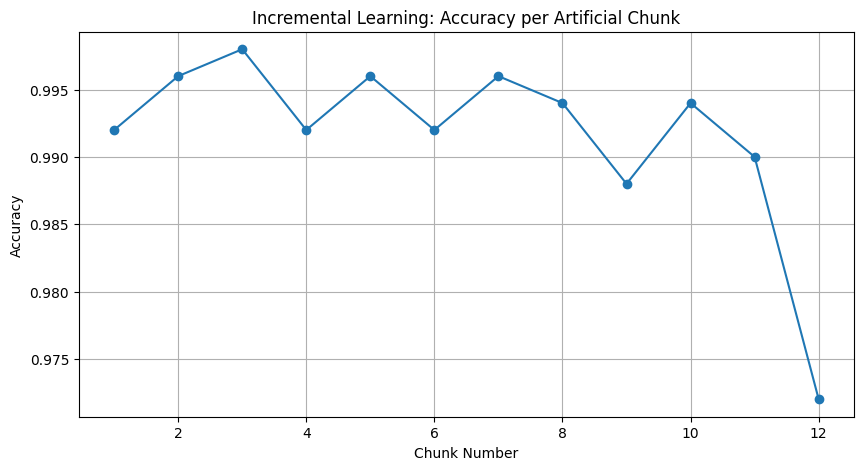

Classification Report on Last Artificial Chunk:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       487
           1       0.00      0.00      0.00        13

    accuracy                           0.97       500
   macro avg       0.49      0.50      0.49       500
weighted avg       0.95      0.97      0.96       500



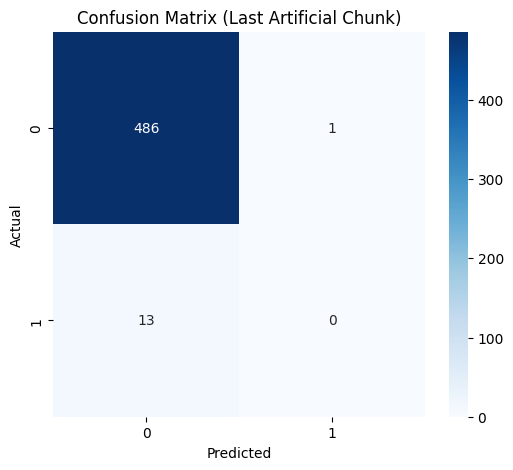

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 1. Gráfico da acurácia incremental por chunk
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(accuracy_history) + 1), accuracy_history, marker='o')
plt.title('Aprendizagem Incremental: Acurácia por Chunk Artificial')
plt.xlabel('Número do Chunk')
plt.ylabel('Acurácia')
plt.grid(True)
plt.show()

# 2. Avaliação no último chunk artificial (proxy para desempenho em teste)
X_eval, y_eval = artificial_chunks[-1]
y_eval_pred = model.predict(X_eval)

print("Relatório de Classificação no Último Chunk Artificial:")
print(classification_report(y_eval, y_eval_pred))

# 3. Matriz de Confusão
cm = confusion_matrix(y_eval, y_eval_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão (Último Chunk Artificial)')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()


## 7. Conclusão

### Apêndice: Geração de Dados Artificiais

Criar cenários artificiais para enriquecer o dataset e melhorar a capacidade de generalização do modelo.

In [ ]:
import numpy as np
import pandas as pd

# Função para criar dados artificiais
np.random.seed(42)
def gerar_dados_artificiais(n=100):
    # Exemplo: 3 sensores, 2 tipos de falha
    sensores = np.random.normal(loc=0, scale=1, size=(n, 3))
    tipo_falha = np.random.choice([0, 1], size=n)  # 0: sem falha, 1: falha
    tempo_uso = np.random.randint(1, 1000, size=n)
    dados = pd.DataFrame(sensores, columns=['sensor_1', 'sensor_2', 'sensor_3'])
    dados['tipo_falha'] = tipo_falha
    dados['tempo_uso'] = tempo_uso
    return dados

# Gerar e exibir dados artificiais
dados_artificiais = gerar_dados_artificiais(200)
dados_artificiais.head()

### Apêndice: Aprendizagem Incremental

Exemplo de processo incremental com dados artificiais.

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split

# Preparar dados (usando os dados artificiais gerados)
X = dados_artificiais[['sensor_1', 'sensor_2', 'sensor_3', 'tempo_uso']]
y = dados_artificiais['tipo_falha']

# Dividir em lotes para aprendizagem incremental
batch_size = 40
n_batches = int(np.ceil(len(X) / batch_size))

# Inicializar modelo incremental
modelo_inc = SGDClassifier(max_iter=1000, tol=1e-3)

for i in range(n_batches):
    start = i * batch_size
    end = start + batch_size
    X_batch = X.iloc[start:end]
    y_batch = y.iloc[start:end]
    modelo_inc.partial_fit(X_batch, y_batch, classes=[0, 1])
    print(f"Treinado com lote {i+1}/{n_batches}")

# Avaliação rápida
y_pred = modelo_inc.predict(X)
print("Acurácia incremental:", (y_pred == y).mean())

## Análise dos Resultados

- O gráfico de acurácia incremental mostra como o modelo evolui à medida que aprende com novos lotes de dados.
- O relatório de classificação e a matriz de confusão do último chunk artificial permitem avaliar o desempenho do modelo em distinguir entre falha e não falha.
- Se a precisão e recall para a classe de falha forem elevados, o modelo é eficaz na deteção de falhas. Caso contrário, recomenda-se ajustar hiperparâmetros, balancear os dados ou criar novas variáveis.

## Conclusão

O processo incremental simula cenários reais de dados em fluxo, permitindo que o modelo se adapte progressivamente. A geração de dados artificiais enriquece o treino e contribui para a robustez do modelo. Para melhores resultados, é importante analisar continuamente as métricas e ajustar o pipeline conforme necessário.